# ReviewLens Exploratory Data Analysis
Dataset: Daraz Labelled Review Dataset with Sentiments and Features (3,923 reviews).

In [1]:
import re, ast, os
from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
COLORS = {"Positive": "#2E8B57", "Neutral": "#9AA0A6", "Negative": "#C0504D"}
os.makedirs("../docs", exist_ok=True)
def save(name): plt.savefig(f"../docs/{name}.png", dpi=150, bbox_inches="tight")

## 1. Load the data

In [5]:
DATA = r"D:\5th Semester\Data Analysis And Visualization\reviewlens\data\Daraz Labelled Review Dataset with Sentiments and Features.xlsx"
df = pd.read_excel(DATA)
df.columns = ["src_row", "product_id", "customer_name", "customer_id", "date",
              "rating", "is_spam", "review", "sentiment", "features"]
df["product_id"] = df["product_id"].astype(str)          # a few product ids are plain numbers
df["date"] = pd.to_datetime(df["date"])
df.head()

,src_row,product_id,customer_name,customer_id,date,rating,is_spam,review,sentiment,features
0,0,TE111EL1KXNGWNAFAMZ,itzmr7,6702,2019-11-09,1,0,mil gya hai acha hai aur toota howa b nai hai,Positive,['toota']
1,1,MI543EL02ACXSNAFAMZ,Afridi,396,2016-11-21,5,0,aram sy pocket may aa jta hai aur quality b ac...,Positive,"['aram', 'pocket', 'quality']"
2,2,MI543EL02ACXSNAFAMZ,Muhammed,3710,2018-10-22,2,0,sb sy achi chez apki customer service bhot ach...,Positive,"['customer', 'products', 'orignal']"
3,3,TE111EL1KXNGWNAFAMZ,Ghazanfar,1860,2017-10-06,3,0,back cover acha hai sai cuts hai aur soft b ha...,Positive,"['back', 'cover', 'cuts', 'soft', 'protector',..."
4,4,SO638EL103OUWNAFAMZ,Murtaza iqbal,3778,2017-08-31,4,0,shru may may thumb grip k khalif thi kyu k ext...,Negative,"['thumb', 'grip', 'chezy', 'stock', 'controlle..."


## 2. Shape and structure

In [6]:
print("Rows, columns:", df.shape)
print("\nMissing values per column:"); print(df.isna().sum())
print("\nUnique products :", df.product_id.nunique())
print("Unique customers:", df.customer_id.nunique())
print("Date range      :", df.date.min().date(), "to", df.date.max().date())
df.dtypes

Rows, columns: (3923, 10)

Missing values per column:
src_row          0
product_id       0
customer_name    0
customer_id      0
date             0
rating           0
is_spam          0
review           0
sentiment        0
features         0
dtype: int64

Unique products : 1066
Unique customers: 2787
Date range      : 2016-02-01 to 2020-01-31


src_row                   int64
product_id               object
customer_name            object
customer_id               int64
date             datetime64[ns]
rating                    int64
is_spam                   int64
review                   object
sentiment                object
features                 object
dtype: object

## 3. Data quality checks

In [7]:
print("Exact duplicate rows         :", df.drop(columns="src_row").duplicated().sum())
print("Repeated review texts        :", df.review.duplicated().sum())
df["word_count"] = df.review.str.split().str.len()
print("\nReview length (words):"); print(df.word_count.describe().round(1))
odd = ~df.product_id.str.match(r"^[A-Z]{2}\d{3}[A-Z]{2}")
print("\nProduct ids not in the usual pattern:", odd.sum())
print("Customer ids with more than one name:", (df.groupby("customer_id").customer_name.nunique() > 1).sum())

Exact duplicate rows         : 0
Repeated review texts        : 65

Review length (words):
count    3923.0
mean       24.5
std        24.4
min         1.0
25%         9.0
50%        15.0
75%        31.0
max       229.0
Name: word_count, dtype: float64

Product ids not in the usual pattern: 181
Customer ids with more than one name: 45


**Finding:** The dataset has 3,923 reviews and 10 columns with no missing values. There are no exact duplicate rows, but 65 review texts appear more than once, so they will be flagged during ETL instead of deleted. 181 product IDs do not follow the standard pattern, and 45 customer IDs appear under more than one name, so both will be cleaned before loading the warehouse. The median review is 15 words while the mean is 24.5, so most reviews are short and a few long ones pull the average up.

## 4. One column at a time

C:\Users\Amna\AppData\Local\Temp\ipykernel_23188\3170802853.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="sentiment", order=order, palette=COLORS, ax=ax[0]); ax[0].set_title("Sentiment label")


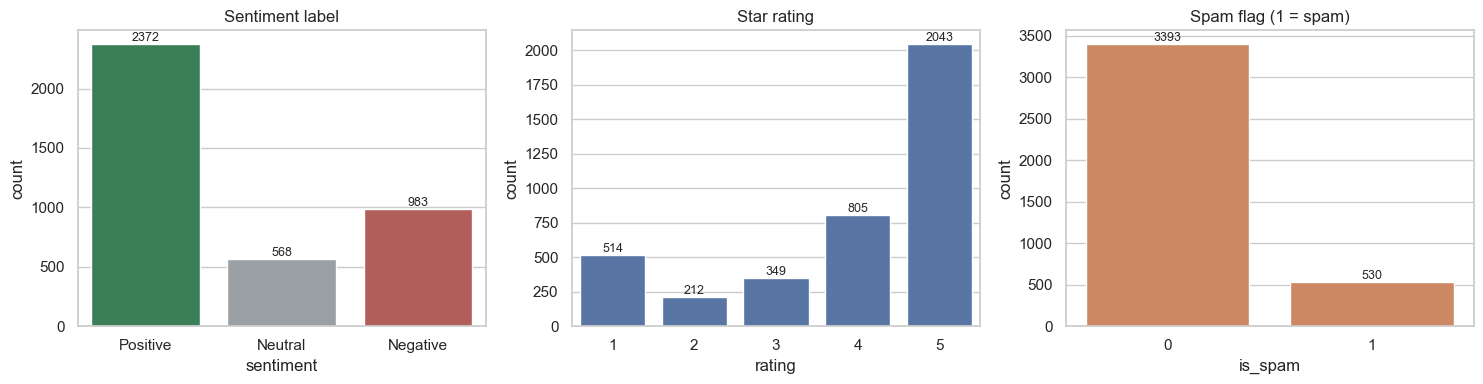

sentiment
Positive    60.5
Negative    25.1
Neutral     14.5
Name: proportion, dtype: float64


In [8]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
order = ["Positive", "Neutral", "Negative"]
sns.countplot(data=df, x="sentiment", order=order, palette=COLORS, ax=ax[0]); ax[0].set_title("Sentiment label")
sns.countplot(data=df, x="rating", color="#4C72B0", ax=ax[1]); ax[1].set_title("Star rating")
sns.countplot(data=df, x="is_spam", color="#DD8452", ax=ax[2]); ax[2].set_title("Spam flag (1 = spam)")
for a in ax:
    for p in a.patches: a.annotate(int(p.get_height()), (p.get_x()+p.get_width()/2, p.get_height()), ha="center", va="bottom", fontsize=9)
plt.tight_layout(); save("01_sentiment_rating_spam"); plt.show()
print((df.sentiment.value_counts(normalize=True)*100).round(1))

**Finding:** The data is skewed positive. 60.5% of reviews are labelled Positive, 25.1% Negative and 14.5% Neutral. Ratings are skewed even more: 5 stars is the most common rating (2,043 reviews, about 52%), and 4 and 5 stars together make up roughly 73%. 530 reviews (13.5%) are flagged as spam. Because the classes are imbalanced, accuracy alone would be misleading for a sentiment model, so F1 per class will be reported as well.

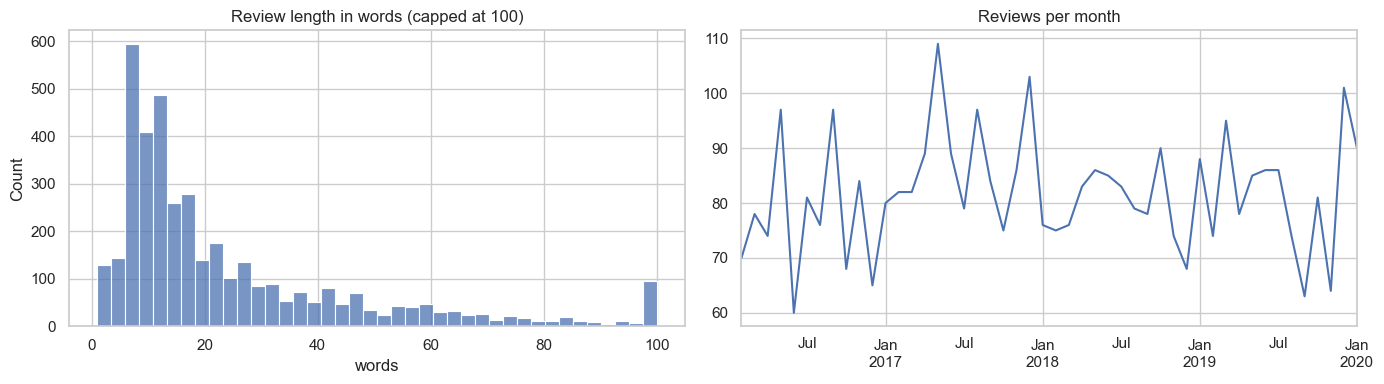

date
2016     850
2017    1055
2018     953
2019     975
2020      90
Name: count, dtype: int64


In [9]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(df.word_count.clip(upper=100), bins=40, color="#4C72B0", ax=ax[0])
ax[0].set_title("Review length in words (capped at 100)"); ax[0].set_xlabel("words")
df.set_index("date").resample("MS").size().plot(ax=ax[1], color="#4C72B0")
ax[1].set_title("Reviews per month"); ax[1].set_xlabel("")
plt.tight_layout(); save("02_length_and_volume"); plt.show()
print(df.date.dt.year.value_counts().sort_index())

**Finding:** Most reviews are short. The length histogram peaks at about 7 to 12 words and has a long tail of detailed reviews; the bar at 100 is only the cap applied to the chart. Review volume is fairly steady at about 60 to 110 per month from 2016 to 2019, with no clear growth trend. 2020 shows only 90 reviews because the data ends in January 2020.

## 5. Two columns together - can we trust the stars?

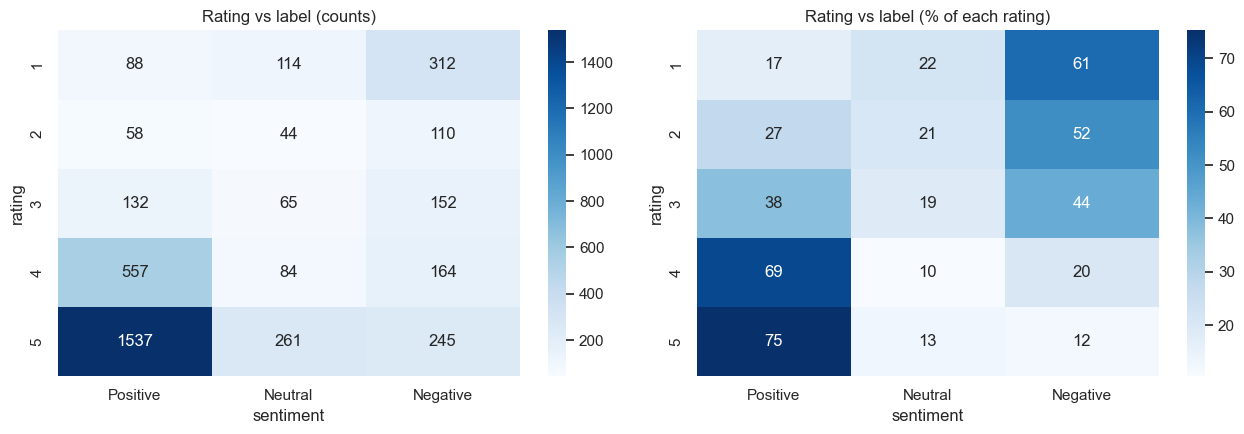

Rating and label disagree on 555 reviews (14.1%)
5-star reviews labelled Negative: 245
1-star reviews labelled Positive: 88


In [10]:
ct = pd.crosstab(df.rating, df.sentiment)[order]
ct_pct = ct.div(ct.sum(axis=1), axis=0) * 100
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.heatmap(ct, annot=True, fmt="d", cmap="Blues", ax=ax[0]); ax[0].set_title("Rating vs label (counts)")
sns.heatmap(ct_pct, annot=True, fmt=".0f", cmap="Blues", ax=ax[1]); ax[1].set_title("Rating vs label (% of each rating)")
plt.tight_layout(); save("03_rating_vs_sentiment"); plt.show()

df["rating_conflict"] = (((df.rating >= 4) & (df.sentiment == "Negative")) |
                         ((df.rating <= 2) & (df.sentiment == "Positive")))
print(f"Rating and label disagree on {df.rating_conflict.sum()} reviews ({df.rating_conflict.mean()*100:.1f}%)")
print("5-star reviews labelled Negative:", ((df.rating==5)&(df.sentiment=="Negative")).sum())
print("1-star reviews labelled Positive:", ((df.rating==1)&(df.sentiment=="Positive")).sum())

**Finding:** Star ratings and text-based labels disagree on 555 reviews (14.1%), including 245 five-star reviews labelled Negative and 88 one-star reviews labelled Positive. Among 5-star reviews 75% are Positive but 12% are Negative; among 1-star reviews 61% are Negative but 17% are Positive. Three-star ratings split almost evenly between Positive and Negative, so they carry little information. This supports the project's premise that star ratings alone are not a reliable measure of customer opinion. The labels come with the dataset and may contain errors, so the disagreement rate will be checked against a hand-labelled sample.

C:\Users\Amna\AppData\Local\Temp\ipykernel_23188\3376749182.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="sentiment", y=df.word_count.clip(upper=120), order=order, palette=COLORS, ax=ax[1]); ax[1].set_title("Review length by sentiment")


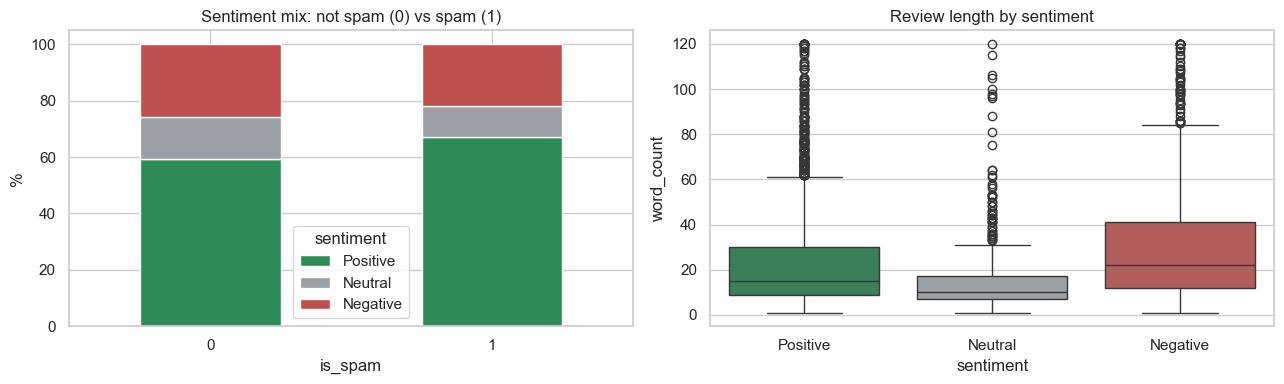

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sp = pd.crosstab(df.is_spam, df.sentiment, normalize="index")[order] * 100
sp.plot(kind="bar", stacked=True, color=[COLORS[c] for c in order], ax=ax[0]); ax[0].set_title("Sentiment mix: not spam (0) vs spam (1)"); ax[0].set_ylabel("%"); ax[0].tick_params(axis="x", rotation=0)
sns.boxplot(data=df, x="sentiment", y=df.word_count.clip(upper=120), order=order, palette=COLORS, ax=ax[1]); ax[1].set_title("Review length by sentiment")
plt.tight_layout(); save("04_spam_and_length_vs_sentiment"); plt.show()

**Finding:** Spam-flagged reviews are more positive than normal reviews: 67.2% of spam reviews are Positive compared with 59.4% of non-spam reviews, and fewer are Negative (21.7% versus 25.6%). This suggests spam reviews lean promotional, so leaving them in would slightly inflate the positive share. Spam rows will be kept in the warehouse but flagged, so analyses can be shown with and without them.

**Finding:** Negative reviews are the longest (median 22 words, mean 31), Positive reviews are shorter (median 15, mean 24), and Neutral reviews are the shortest (median 10, mean 15). Customers who are unhappy tend to explain their problem in more detail, while neutral reviews are often brief remarks. Review length can therefore be a useful feature for the sentiment model. All three groups have many long outliers, which is normal for text lengths.

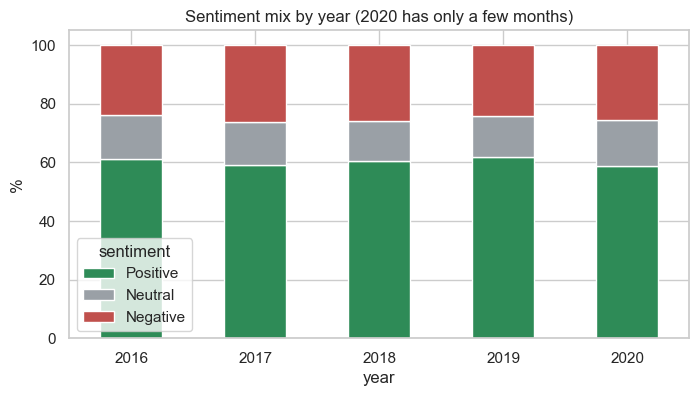

In [12]:
df["year"] = df.date.dt.year
yr = pd.crosstab(df.year, df.sentiment, normalize="index")[order] * 100
yr.plot(kind="bar", stacked=True, color=[COLORS[c] for c in order], figsize=(8, 4))
plt.title("Sentiment mix by year (2020 has only a few months)"); plt.ylabel("%"); plt.xticks(rotation=0)
save("05_sentiment_by_year"); plt.show()

**Finding:** The sentiment mix is stable across the years. Positive stays between about 59% and 62%, and Negative between about 24% and 26%, so there is no clear trend of customers becoming more or less satisfied over time. This means the time dimension is useful for reporting but is not the main driver of sentiment. 2020 contains only January, so its small sample should not be over-interpreted.

## 6. Product category (inferred from Product_ID)
Characters 6-7 of the product id look like a category code. This is an inference - say so in your report.

category
Fashion             1088
Electronics          743
Health & Beauty      532
Other                467
Home & Living        300
Sports & Outdoor     276
Toys & Baby          213
Unknown              181
Media & Gaming       123
Name: count, dtype: int64


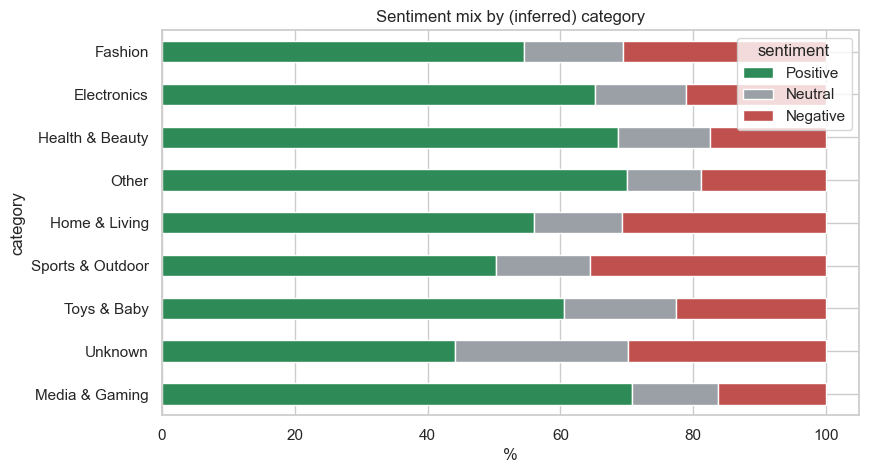

In [13]:
NAMES = {"FA": "Fashion", "HB": "Health & Beauty", "EL": "Electronics", "ME": "Media & Gaming",
         "HL": "Home & Living", "TB": "Toys & Baby", "SP": "Sports & Outdoor", "OT": "Other"}
df["category"] = df.product_id.str.extract(r"^[A-Z]{2}\d{3}([A-Z]{2})")[0].map(NAMES).fillna("Unknown")
print(df.category.value_counts())
cat = pd.crosstab(df.category, df.sentiment, normalize="index")[order] * 100
cat = cat.loc[df.category.value_counts().index]
cat.plot(kind="barh", stacked=True, color=[COLORS[c] for c in order], figsize=(9, 5))
plt.title("Sentiment mix by (inferred) category"); plt.xlabel("%"); plt.gca().invert_yaxis()
save("06_sentiment_by_category"); plt.show()

**Finding:** Fashion (1,088 reviews) and Electronics (743) make up almost half of the dataset, and Media & Gaming is the smallest category (123). 181 reviews have no usable category and fall into "Unknown". The uneven sizes mean percentages for small categories are less stable than for large ones.

**Finding:** Sentiment differs clearly by category, with the negative share ranging from 16.3% in Media & Gaming to 35.5% in Sports & Outdoor. Fashion (30.6% negative, 1,088 reviews) and Home & Living (30.7%) are also above the overall average of 25.1%, while Health & Beauty (17.5%) and Electronics (21.1%) are better than average. Fashion is the largest category, so its higher complaint rate affects the overall picture most. The "Unknown" group (181 reviews) is the most negative and the most neutral, but it is a mix of products with unusable IDs, so it should be read with caution. Categories are inferred from product ID codes and not from an official field, so these results are indicative until the category mapping is validated.

## 7. Text - keywords
The dataset's `Features` column already lists keywords per review.

Reviews with no keyword: 202


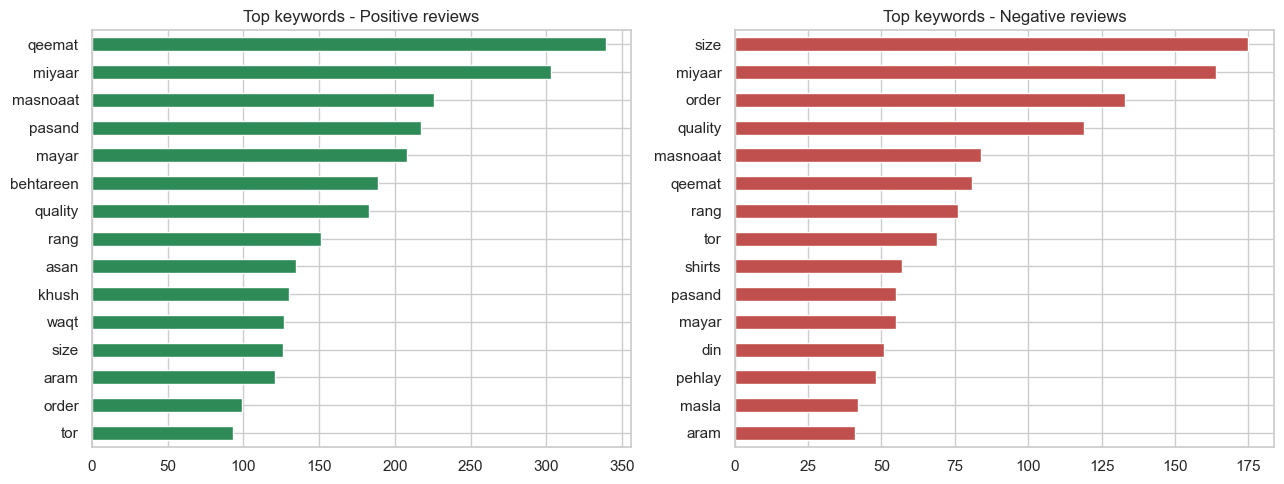

In [14]:
def parse(s):
    try: return [w.strip().lower() for w in ast.literal_eval(s) if str(w).strip()]
    except Exception: return []
df["kw"] = df.features.map(parse)
print("Reviews with no keyword:", (df.kw.str.len() == 0).sum())

def top(label, n=15):
    c = Counter(w for ws in df[df.sentiment == label].kw for w in ws)
    return pd.Series(dict(c.most_common(n)))
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for a, lab in zip(ax, ["Positive", "Negative"]):
    top(lab).sort_values().plot(kind="barh", color=COLORS[lab], ax=a); a.set_title(f"Top keywords - {lab} reviews")
plt.tight_layout(); save("07_top_keywords"); plt.show()

**Finding:** The most frequent keywords are Roman Urdu words that appear in both positive and negative reviews, for example *qeemat* (price), *miyaar* (standard/quality), *masnoaat* (products), *pasand* (liking) and *quality*. This shows that customers talk about the same topics whether they are happy or not, so raw frequency does not separate good from bad reviews. The clearest difference is *size*, which is the top keyword in negative reviews (about 175 mentions) but ranks lower in positive ones, pointing to sizing and fit as a common complaint. *Order*, *rang* (colour) and *shirts* also appear high in negative reviews, hinting at order, colour and clothing issues.

In [15]:
# Words that separate the two groups (a word can be frequent in BOTH, so raw counts mislead)
import numpy as np
pos = Counter(w for ws in df[df.sentiment == "Positive"].kw for w in ws)
neg = Counter(w for ws in df[df.sentiment == "Negative"].kw for w in ws)
nP, nN = sum(pos.values()), sum(neg.values())
rows = [(w, pos[w], neg[w], np.log(((pos[w]+1)/nP) / ((neg[w]+1)/nN))) for w in set(pos) | set(neg) if pos[w] + neg[w] >= 15]
lo = pd.DataFrame(rows, columns=["word", "pos", "neg", "log_odds"]).sort_values("log_odds")
print("Most NEGATIVE words:"); print(lo.head(10).to_string(index=False))
print("\nMost POSITIVE words:"); print(lo.tail(10).to_string(index=False))

Most NEGATIVE words:
   word  pos  neg  log_odds
 bakwas    0   27 -3.998595
 bekaar    1   20 -3.017765
  bekar    1   18 -2.917682
   toot    3   28 -2.647392
 mayoos    5   31 -2.340367
    pic    4   18 -2.001391
 ghalat    7   25 -1.845045
dobarah    6   21 -1.811523
   buri    6   20 -1.765003
    log    7   15 -1.359537

Most POSITIVE words:
     word  pos  neg  log_odds
   angaiz   64    4  1.898559
   result   25    1  1.898559
    sound   28    1  2.007758
   kamray   15    0  2.106198
zabardast   80    3  2.341765
     nice   20    0  2.378132
  kitchen   20    0  2.378132
   timing   21    0  2.424652
    kamal   25    0  2.591706
    zaiqa   34    0  2.888958


**Finding:** Scoring words by how strongly they favour one class gives a much clearer picture than raw counts. The most negative words are *bakwas* (rubbish), *bekaar* and *bekar* (useless), *toot* (broken), *mayoos* (disappointed) and *ghalat* (wrong). The most positive are *zaiqa* (taste), *kamal* (wonderful), *zabardast* (awesome), *angaiz* and *nice*. Negative words describe product defects and disappointment, while positive words relate to taste, performance and praise. Words such as *kitchen*, *timing* and *sound* appear only in positive reviews, suggesting certain product types are rated more favourably. These sentiment-bearing words are the best candidates for the keyword dimension and the sentiment model's features.

## 8. Word clouds

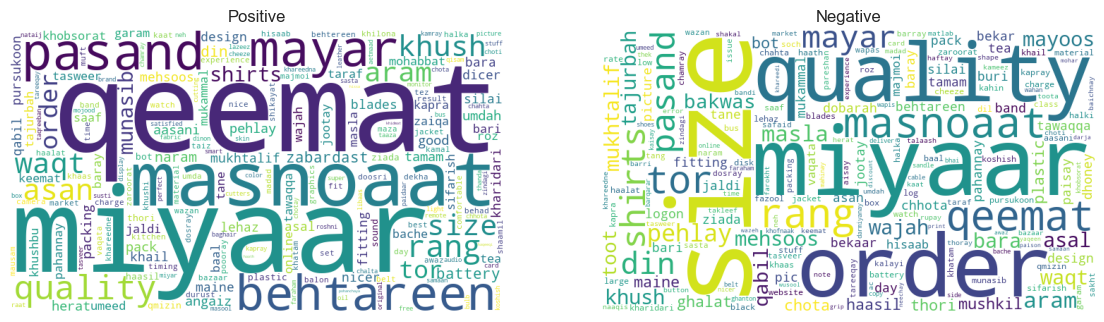

In [16]:
from wordcloud import WordCloud
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for a, lab in zip(ax, ["Positive", "Negative"]):
    freq = dict(Counter(w for ws in df[df.sentiment == lab].kw for w in ws))
    a.imshow(WordCloud(width=700, height=400, background_color="white").generate_from_frequencies(freq)); a.axis("off"); a.set_title(lab)
save("08_wordclouds"); plt.show()

**Finding:** The positive and negative word clouds look similar because the dataset's keywords are mostly neutral topic words (price, quality, size, colour). The negative cloud is dominated by *size*, *quality*, *miyaar* and *order*, while the positive cloud is dominated by *qeemat*, *miyaar*, *masnoaat* and *behtareen* (excellent). Word clouds show frequency only, so the log-odds table below is needed to identify words that truly distinguish the two groups.

## 9. Products and customers

Reviews per product - median: 1.0 | max: 173
Products with only one review: 543 of 1066

Top 10 products by review count:
product_id
MA305FA1KY528NAFAMZ    173
SU455FA18NJ18NAFAMZ    105
GE310FA1HFXXGNAFAMZ     88
TH065EL19ZT5GNAFAMZ     72
MI543EL1HRDD4NAFAMZ     45
OA551FA1B35TGNAFAMZ     45
NI613HL000SACNAFAMZ     44
KE347HBELYK4NAFAMZ      38
GL296HB01CT30NAFAMZ     37
SH069FA039PJONAFAMZ     37
Name: count, dtype: int64

Customers with 3+ reviews: 193


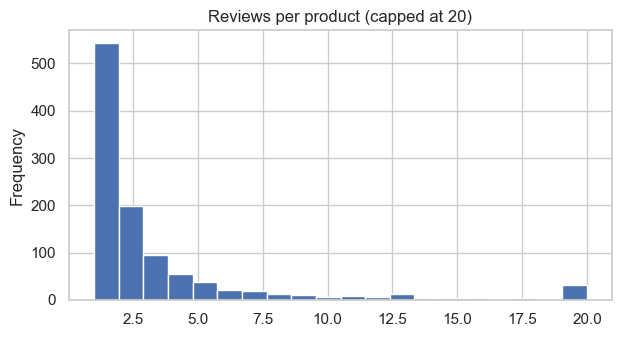

In [17]:
pc = df.product_id.value_counts()
print("Reviews per product - median:", pc.median(), "| max:", pc.max())
print("Products with only one review:", (pc == 1).sum(), "of", len(pc))
print("\nTop 10 products by review count:"); print(pc.head(10))
cc = df.customer_id.value_counts()
print("\nCustomers with 3+ reviews:", (cc >= 3).sum())
pc.clip(upper=20).plot(kind="hist", bins=20, figsize=(7, 3.5), color="#4C72B0")
plt.title("Reviews per product (capped at 20)"); save("09_reviews_per_product"); plt.show()

**Finding:** Review counts per product are heavily skewed. The median product has only 1 review, and 543 of 1,066 products (about 51%) have just one. The 10 most reviewed products account for 684 reviews (17.4% of the dataset), and one product alone has 173. Product-level conclusions are therefore reliable only for the small number of heavily reviewed products, and analysis should mostly be done at category level. 193 customers wrote three or more reviews, which could be checked later for unusual behaviour.

## 10. Summary of findings
- Sentiment is skewed positive (60.5% Positive, 25.1% Negative, 14.5% Neutral), so F1 per class will be reported.
- Star ratings and labels disagree on 14.1% of reviews, supporting the idea that stars alone are unreliable.
- Spam reviews (13.5%) are more positive than non-spam reviews and will be flagged.
- Negative reviews are longer than positive ones.
- Sentiment is stable over time but differs by category: Sports & Outdoor, Home & Living and Fashion have the most complaints.
- Raw word frequency does not separate good from bad; log-odds words such as bakwas, bekaar, toot (negative) and zabardast, kamal, zaiqa (positive) do.
- Most products have one review, so analysis will focus on categories.